In [10]:
import numpy as np
import pandas as pd

In [11]:
from pathlib import Path

df = pd.read_csv("D:/EMI_dataset.csv")

OUT_DIR = Path("D:/emi-project/data")   # any folder you like for output files
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [12]:
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("D:/EMI_dataset.csv")
print(df.shape)
print("duplicates:", df.duplicated().sum())
print(df.isna().sum()[df.isna().sum() > 0])
df.describe().T

(400400, 27)
duplicates: 400
education         2000
monthly_salary    3206
monthly_rent      2001
credit_score      2403
bank_balance      4005
dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,400400.0,42.494323,10.388246,25.0,33.0,42.0,51.0,60.0
monthly_salary,397194.0,54076.815863,31132.928250,15000.0,32200.0,46600.0,67500.0,200000.0
years_of_employment,400400.0,13.267465,8.561015,0.0,6.0,12.0,19.0,35.0
monthly_rent,398399.0,4333.025685,6993.103874,0.0,0.0,0.0,7300.0,59900.0
family_size,400400.0,3.998731,2.000475,1.0,2.0,4.0,6.0,7.0
dependents,400400.0,1.499416,1.605591,0.0,0.0,1.0,2.0,6.0
school_fees,400400.0,3000.267652,4093.504613,0.0,0.0,1400.0,4218.0,23994.0
college_fees,400400.0,599.466499,1683.964618,0.0,0.0,0.0,0.0,7999.0
travel_expenses,400400.0,2704.496004,1898.285341,300.0,1400.0,2200.0,3500.0,16000.0
groceries_utilities,400400.0,11850.476773,5653.298174,2300.0,8000.0,10700.0,14300.0,49500.0


In [13]:
df = df.drop_duplicates().reset_index(drop=True)

# salary: median within employment type; other numerics: overall median
df["monthly_salary"] = df["monthly_salary"].fillna(df.groupby("employment_type")["monthly_salary"].transform("median"))
for c in ["bank_balance", "credit_score"]:
    df[c] = df[c].fillna(df[c].median())

# rent: only renters pay rent
df.loc[df["house_type"] != "Rented", "monthly_rent"] = df["monthly_rent"].fillna(0)
df["monthly_rent"] = df["monthly_rent"].fillna(df.loc[df.house_type == "Rented", "monthly_rent"].median())

df["education"] = df["education"].fillna(df["education"].mode()[0])
df["credit_score"] = df["credit_score"].clip(300, 850).round().astype(int)

assert df.isna().sum().sum() == 0
assert df["age"].between(25, 60).all()
print(df.shape)

(400000, 27)


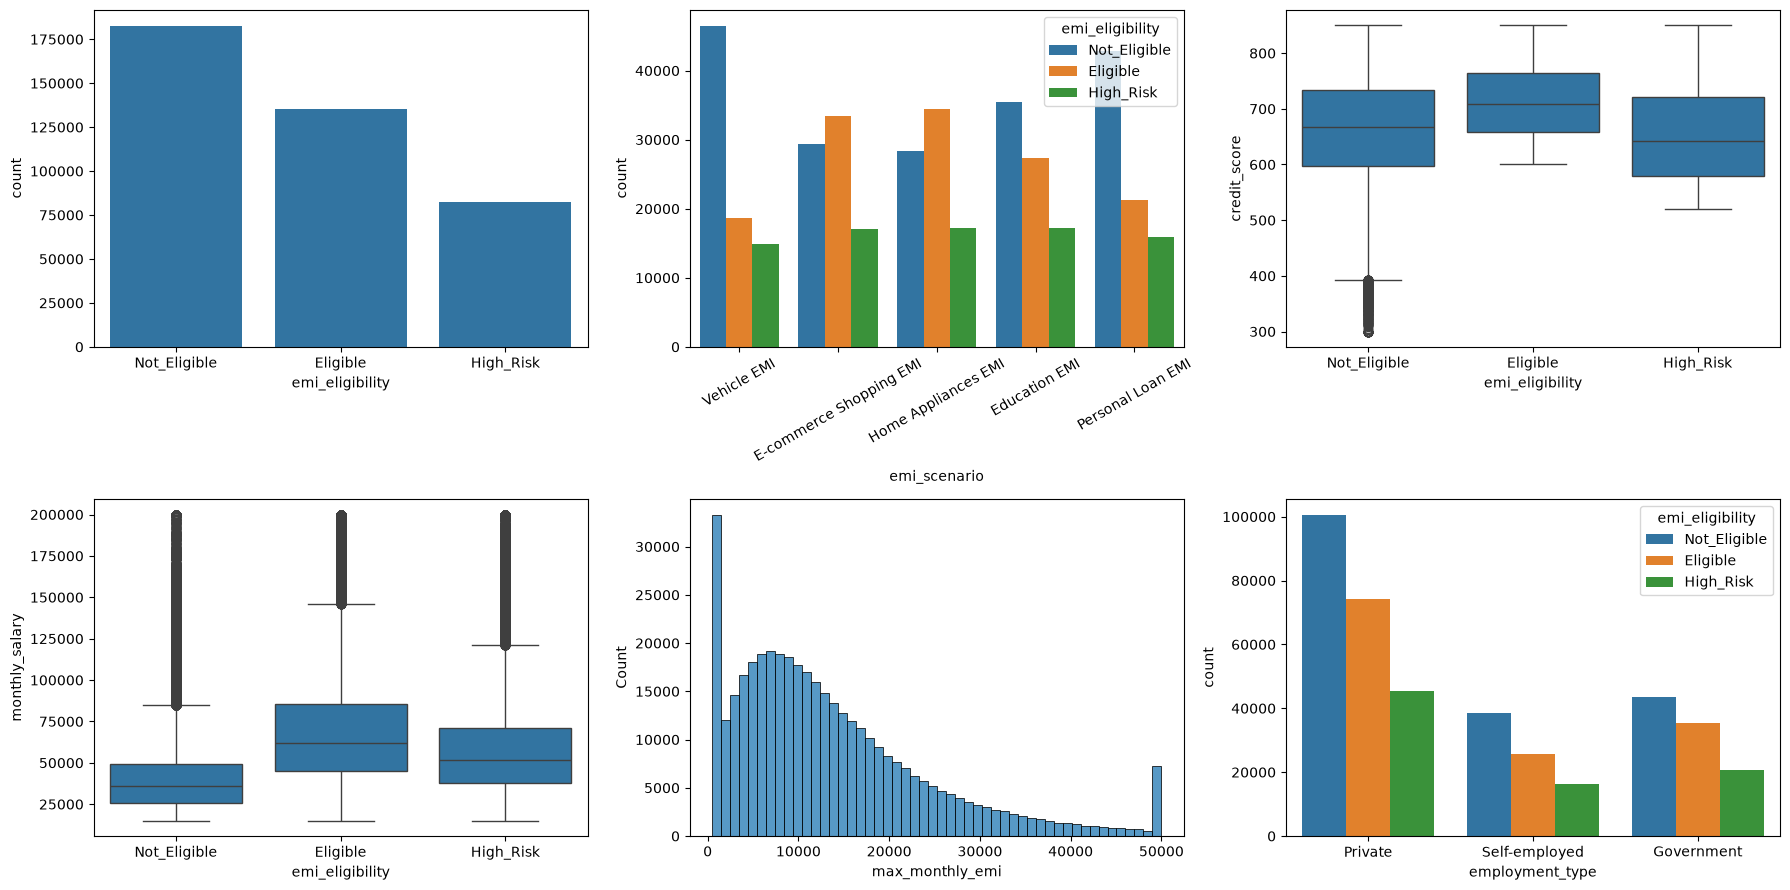

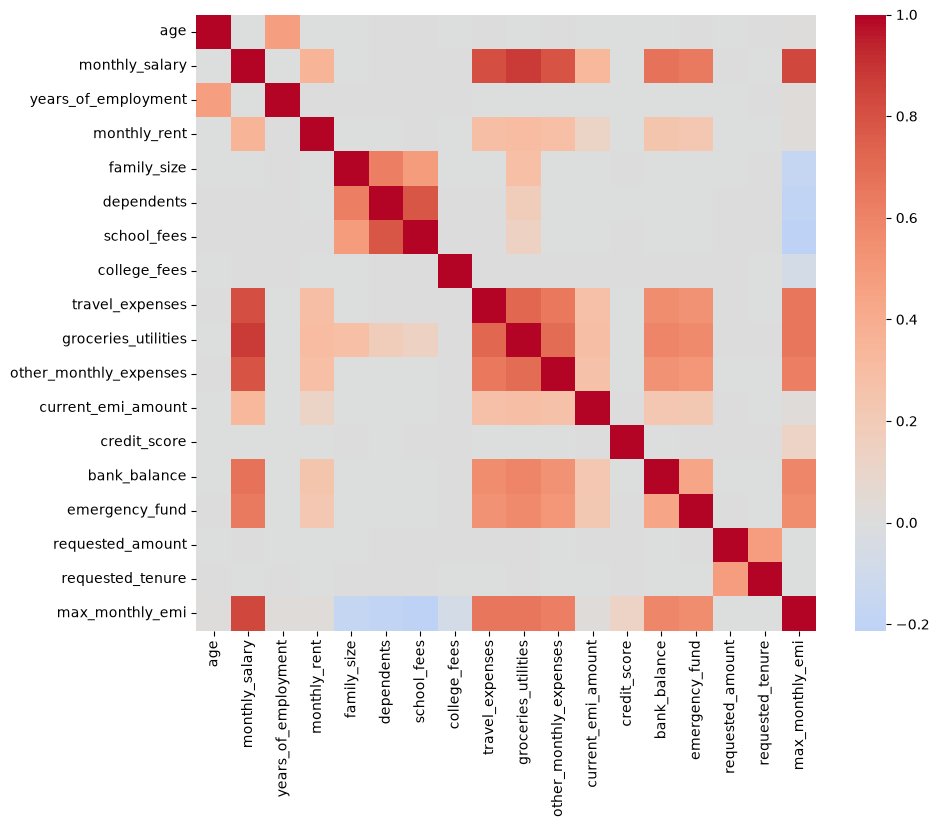

emi_eligibility          Eligible  High_Risk  Not_Eligible
emi_scenario                                              
E-commerce Shopping EMI      0.42       0.21          0.37
Education EMI                0.34       0.21          0.44
Home Appliances EMI          0.43       0.22          0.35
Personal Loan EMI            0.27       0.20          0.53
Vehicle EMI                  0.23       0.19          0.58


In [14]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
sns.countplot(data=df, x="emi_eligibility", ax=ax[0,0])
sns.countplot(data=df, x="emi_scenario", hue="emi_eligibility", ax=ax[0,1]); ax[0,1].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="emi_eligibility", y="credit_score", ax=ax[0,2])
sns.boxplot(data=df, x="emi_eligibility", y="monthly_salary", ax=ax[1,0])
sns.histplot(df["max_monthly_emi"], bins=50, ax=ax[1,1])
sns.countplot(data=df, x="employment_type", hue="emi_eligibility", ax=ax[1,2])
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes("number").corr(), cmap="coolwarm", center=0)
plt.show()

print(pd.crosstab(df.emi_scenario, df.emi_eligibility, normalize="index").round(2))

In [15]:
def add_features(d):
    d = d.copy()
    s = d["monthly_salary"]
    d["total_expenses"] = d[["monthly_rent", "school_fees", "college_fees", "travel_expenses",
                             "groceries_utilities", "other_monthly_expenses"]].sum(axis=1)
    d["requested_emi"] = d["requested_amount"] / d["requested_tenure"]

    d["expense_to_income"] = d["total_expenses"] / s
    d["existing_emi_to_income"] = d["current_emi_amount"] / s
    d["requested_emi_to_income"] = d["requested_emi"] / s
    d["dti_after_loan"] = (d["current_emi_amount"] + d["requested_emi"]) / s
    d["disposable_income"] = s - d["total_expenses"] - d["current_emi_amount"]
    d["affordability_ratio"] = d["requested_emi"] / d["disposable_income"].clip(lower=1)
    d["savings_to_salary"] = (d["bank_balance"] + d["emergency_fund"]) / s
    d["employment_stability"] = d["years_of_employment"] / (d["age"] - 20)
    d["credit_risk_band"] = pd.cut(d["credit_score"], [0, 580, 670, 740, 900],
                                   labels=["Poor", "Fair", "Good", "Excellent"]).astype(str)
    # interactions
    d["credit_x_disposable"] = d["credit_score"] * d["disposable_income"] / 1e5
    d["dependents_x_expense"] = d["dependents"] * d["expense_to_income"]
    return d

df_fe = add_features(df)
df_fe.to_csv("D:/clean_featured.csv", index=False)
df_fe.filter(like="_to_").describe().T

,count,mean,std,min,25%,50%,75%,max
expense_to_income,400000.0,0.517986,0.210537,0.083871,0.364078,0.482353,0.619658,2.800903
existing_emi_to_income,400000.0,0.070039,0.097516,0.000000,0.000000,0.000000,0.143322,0.965591
requested_emi_to_income,400000.0,0.362330,0.434995,0.002174,0.107632,0.223056,0.446735,8.033333
savings_to_salary,400000.0,9.266429,3.794269,0.207265,6.364865,9.247278,12.129530,66.933333


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# IMPORTANT: no target leakage
#   classification -> drop max_monthly_emi ; regression -> drop emi_eligibility
y_clf, y_reg = df_fe["emi_eligibility"], df_fe["max_monthly_emi"]
X = df_fe.drop(columns=["emi_eligibility", "max_monthly_emi"])

X_tr, X_tmp, ycl_tr, ycl_tmp, yr_tr, yr_tmp = train_test_split(
    X, y_clf, y_reg, test_size=0.30, stratify=y_clf, random_state=42)
X_val, X_te, ycl_val, ycl_te, yr_val, yr_te = train_test_split(
    X_tmp, ycl_tmp, yr_tmp, test_size=0.50, stratify=ycl_tmp, random_state=42)
print(len(X_tr), len(X_val), len(X_te))

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
preprocessor.fit(X_tr)          # fit on TRAIN only

280000 60000 60000


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``